# Pemetaan Penggunaan dan Tutupan Lahan (LULC) Jawa Timur

## Business Understanding

### Latar Belakang

Permukaan Bumi memiliki beragam jenis tutupan lahan yang mencerminkan kondisi lingkungan dan aktivitas manusia. Provinsi Jawa Timur memiliki wilayah pertanian, permukiman, hutan, mangrove, serta perairan yang tersebar di berbagai daerah. Keberagaman tersebut menjadikan pemetaan tutupan lahan (*Land Use and Land Cover* / LULC) penting untuk memahami kondisi wilayah dan mendukung perencanaan tata ruang serta kebijakan pengelolaan lingkungan.

Melalui citra satelit **Sentinel-2 Level-2A**, berbagai objek permukaan Bumi dapat dikenali berdasarkan karakteristik pantulan spektralnya. Dengan memanfaatkan Sistem Informasi Geografis (SIG) dan algoritma *Machine Learning*, khususnya **Random Forest**, proses klasifikasi dapat dilakukan secara sistematis untuk membedakan enam kelas tutupan lahan, yaitu **Sawah, Bangunan, Hutan (Lahan Hijau), Mangrove, Laut (Perairan Terbuka), dan Danau (Ranu)**.

### Tujuan Analisis

1. **Melakukan Klasifikasi Tutupan Lahan:** Mengidentifikasi enam kelas tutupan lahan di wilayah Jawa Timur berdasarkan fitur spektral Sentinel-2 menggunakan algoritma *Machine Learning*, serta mengevaluasi hasil klasifikasi melalui data *training*, *testing*, dan metrik akurasi.

2. **Menyajikan Informasi Spasial:** Memvisualisasikan hasil klasifikasi dalam bentuk peta interaktif menggunakan **Folium/Leaflet** dengan latar citra satelit, serta mengembangkan aplikasi berbasis **Streamlit** dan dokumentasi melalui **Jupyter Book**.

Hasil analisis ini diharapkan dapat memberikan gambaran mengenai persebaran tutupan lahan pada wilayah yang diteliti serta menjadi informasi pendukung dalam memahami pemanfaatan ruang, pengelolaan lingkungan, dan perencanaan kebijakan tata ruang di Jawa Timur.

## Data Understanding
### Deskripsi Dataset dan Label Kelas

Eksperimen ini menggunakan total 300 data titik sampel koordinat. Penentuan kelas Klasifikasi Penutup Lahan yang telah disesuaikan dengan lanskap Jawa Timur:

| Label | Kelas | Deskripsi |
|---:|---|---|
| 1 | **Sawah** | Area pertanian yang digunakan untuk budidaya padi. |
| 2 | **Bangunan** | Kawasan terbangun seperti permukiman, gedung, jalan, dan fasilitas lainnya. |
| 3 | **Hutan** | Wilayah dengan vegetasi rapat seperti hutan dan kawasan hijau dengan tutupan pohon dominan. |
| 4 | **Mangrove** | Vegetasi mangrove yang berada di kawasan pesisir dan daerah pasang surut. |
| 5 | **Danau** | Badan air tawar seperti danau, waduk, telaga, atau bendungan. |
| 6 | **Laut** | Perairan laut terbuka yang berada di wilayah pesisir Jawa Timur. |

### Ekstraksi Fitur

**Band Spektral Sentinel-2A:**
Citra satelit bersumber dari sensor **Multispectral Instrument (MSI)** pada wahana **Sentinel-2A Level-2A** (*Copernicus Data Space Ecosystem* - CDSE) dengan koreksi atmosfer *Bottom-of-Atmosphere* (BOA):

* **B02 (Blue - 490 nm)**: Resolusi 10 meter. Berguna untuk mendeteksi badan air jernih dan hamburan partikel atmosfer.
* **B03 (Green - 560 nm)**: Resolusi 10 meter. Puncak pantulan klorofil daun pada spektrum tampak dan deteksi sedimen perairan.
* **B04 (Red - 665 nm)**: Resolusi 10 meter. Pita serapan utama klorofil; pembeda tajam antara vegetasi hidup dan material tanah terbuka/bangunan.
* **B08 (Near Infrared / NIR - 842 nm)**: Resolusi 10 meter. Pantulan sangat tinggi dari struktur sel mesofil daun; diserap hampir total oleh air jernih.
* **B11 (Short-Wave Infrared / SWIR - 1610 nm)**: Resolusi 20 meter (di-resample ke 10 m). Sensitif terhadap kelembapan air pada tanah dan vegetasi, serta reflektansi material atap/beton.

**Indeks Transformasi (Rumus Spektral):**

Untuk mempermudah algoritma dalam mengenali pola, fitur spektral dasar dikalkulasikan ke dalam dua metrik indeks matematis:

1. **NDVI (*Normalized Difference Vegetation Index*)**
   Mengukur tingkat kehijauan, kerapatan, dan kesehatan vegetasi.
   > **Rumus:** 
   
   $$NDVI = \frac{B08 - B04}{B08 + B04}$$

2. **NDWI (*Normalized Difference Water Index*)**
   Mendeteksi fitur kebasahan dan badan air secara tegas, sembari meminimalisir efek pantulan dari tanah maupun vegetasi terrestrial.
   > **Rumus:** 
   
   $$NDWI = \frac{B03 - B08}{B03 + B08}$$

## Data Collection

### Import Library

In [7]:
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
import openeo
import folium
import matplotlib.pyplot as plt
import joblib

from shapely.validation import make_valid
from rasterio.mask import mask as rio_mask
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

### Membaca Polygon Ground Truth

Data ground truth dari enam kelas tutupan lahan dibaca, diberi label, lalu digabungkan menjadi satu GeoDataFrame.

In [8]:
DATA = Path('C:\\project\\PSD\\data')
HASIL = Path('C:\\project\\PSD\\hasil\\dataset')
HASIL.mkdir(exist_ok=True)

SUMBER = {
    'Sawah': DATA / '50_sawah.zip',
    'non-Sawah': DATA / '50_nonsawah.zip',
}

LABEL = {
    'Sawah': 1,
    'non-Sawah': 2,
}

bagian = []

for kelas, file in SUMBER.items():
    g = gpd.read_file(f'zip://{file.as_posix()}').to_crs('EPSG:4326')
    g = g[g.geometry.notna() & ~g.geometry.is_empty].copy()
    g['geometry'] = g.geometry.apply(lambda x: x if x.is_valid else make_valid(x))
    g['label_teks'] = kelas
    g['label'] = LABEL[kelas]
    g['poligon_id'] = [f'{kelas}_{i:04d}' for i in range(len(g))]
    bagian.append(g[['poligon_id', 'label', 'label_teks', 'geometry']])

gdf = gpd.GeoDataFrame(
    pd.concat(bagian, ignore_index=True),
    crs='EPSG:4326'
)

print('Total polygon:', len(gdf))
print(gdf['label_teks'].value_counts())

Total polygon: 100
label_teks
Sawah        50
non-Sawah    50
Name: count, dtype: int64


### Akuisisi Citra Sentinel-2 dengan openEO

Citra **Sentinel-2 Level-2A** diperoleh melalui **openEO Copernicus** berdasarkan wilayah dan periode pengamatan. Data diproses dengan penyaringan awan dan komposit median, kemudian diunduh dalam format **GeoTIFF (.tif)** untuk klasifikasi tutupan lahan.

In [ ]:
minx, miny, maxx, maxy = gdf.total_bounds

bbox = {
    'west': float(minx),
    'south': float(miny),
    'east': float(maxx),
    'north': float(maxy),
    'crs': 'EPSG:4326'
}

connection = openeo.connect('https://openeo.dataspace.copernicus.eu')
connection.authenticate_oidc()

cube = connection.load_collection(
    'SENTINEL2_L2A',
    spatial_extent=bbox,
    temporal_extent=['2026-01-01', '2026-01-30'],
    bands=['B02', 'B03', 'B04', 'B08', 'B11', 'SCL'],
    max_cloud_cover=30
)

scl = cube.band('SCL')
mask_awan = (scl == 1) | (scl == 3) | (scl == 8) | (scl == 9) | (scl == 10)

cube = cube.filter_bands(['B02', 'B03', 'B04', 'B08', 'B11']).mask(mask_awan)
cube = cube.median_time()
cube = cube.resample_spatial(resolution=0.0002, projection=4326)
cube = cube.save_result(format='GTiff')

job = cube.execute_batch(title='UTS_Sentinel2_KNN')
job.get_results().download_file('hasil_citra_klasifikasi.tif')

### Ekstraksi Piksel dari Polygon

Setiap piksel Sentinel-2 yang berada di dalam polygon menjadi satu baris dataset. Maksimal **1000 piksel per polygon** digunakan agar polygon yang sangat luas tidak mendominasi dataset.

In [15]:
FILE_TIF = 'C:\project\PSD\hasil_citra_klasifikasi.tif'
BANDS = ['B02', 'B03', 'B04', 'B08', 'B11']

rng = np.random.default_rng(42)
potongan = []

with rasterio.open(FILE_TIF) as src:
    gdf_raster = gdf.to_crs(src.crs)

    for _, row in gdf_raster.iterrows():
        try:
            arr, transform = rio_mask(
                src,
                [row.geometry],
                crop=True,
                filled=False
            )
        except ValueError:
            continue

        data = np.ma.getdata(arr[:5]).astype(float)
        masker = np.ma.getmaskarray(arr[:5]).any(axis=0)

        valid = (
            ~masker &
            np.isfinite(data).all(axis=0) &
            (data > 0).all(axis=0)
        )

        r, c = np.nonzero(valid)

        if len(r) == 0:
            continue

        if len(r) > 1000:
            pilih = rng.choice(len(r), 1000, replace=False)
            r = r[pilih]
            c = c[pilih]

        nilai = data[:, r, c].T
        xs, ys = rasterio.transform.xy(transform, r, c)

        temp = pd.DataFrame(nilai, columns=BANDS)
        temp['poligon_id'] = row['poligon_id']
        temp['label'] = row['label']
        temp['label_teks'] = row['label_teks']
        temp['lon'] = np.asarray(xs)
        temp['lat'] = np.asarray(ys)

        potongan.append(temp)

df = pd.concat(potongan, ignore_index=True)

print('Jumlah piksel hasil ekstraksi:', len(df))

<>:1: SyntaxWarning: invalid escape sequence '\p'
<>:1: SyntaxWarning: invalid escape sequence '\p'
C:\Users\Administrator\AppData\Local\Temp\ipykernel_14244\3823425408.py:1: SyntaxWarning: invalid escape sequence '\p'
  FILE_TIF = 'C:\project\PSD\hasil_citra_klasifikasi.tif'


Jumlah piksel hasil ekstraksi: 95


### Menghitung Indeks Spektral dan Membuat `dataset.csv`

Indeks spektral adalah nilai yang digunakan untuk membedakan jenis permukaan bumi berdasarkan pantulan cahaya satelit. **NDVI** menunjukkan tingkat kehijauan tanaman, **NDWI dan MNDWI** membantu mengenali perairan, sedangkan **NDBI** membantu mendeteksi kawasan bangunan. `dataset.csv` merupakan tabel yang menyimpan nilai-nilai tersebut beserta kelas lahannya untuk digunakan dalam klasifikasi.

In [16]:
e = 1e-9

df['NDVI'] = (df['B08'] - df['B04']) / (df['B08'] + df['B04'] + e)
df['NDWI'] = (df['B03'] - df['B08']) / (df['B03'] + df['B08'] + e)
df['MNDWI'] = (df['B03'] - df['B11']) / (df['B03'] + df['B11'] + e)
df['NDBI'] = (df['B11'] - df['B08']) / (df['B11'] + df['B08'] + e)

df = df.replace([np.inf, -np.inf], np.nan).dropna()

df.to_csv(HASIL / 'dataset.csv', index=False)

print('dataset.csv berhasil dibuat')

dataset.csv berhasil dibuat


### Karakteristik Dataset Ground Truth

In [17]:
print(f'Jumlah baris (piksel): {df.shape[0]:,}')
print(f'Jumlah kolom         : {df.shape[1]}')
print(f'Jumlah polygon       : {df["poligon_id"].nunique():,}')
print(f'Jumlah kelas         : {df["label_teks"].nunique()}')

df.head()

Jumlah baris (piksel): 95
Jumlah kolom         : 14
Jumlah polygon       : 60
Jumlah kelas         : 2


,B02,B03,B04,B08,B11,poligon_id,label,label_teks,lon,lat,NDVI,NDWI,MNDWI,NDBI
0,470.0,748.0,563.0,2890.0,1786.0,Sawah_0000,1,Sawah,112.715289,-7.140258,0.673907,-0.588785,-0.409629,-0.236099
1,539.0,936.0,773.0,3865.0,2421.0,Sawah_0001,1,Sawah,112.718289,-7.142858,0.666667,-0.610081,-0.442359,-0.229717
2,541.0,867.0,757.0,3569.0,2404.0,Sawah_0001,1,Sawah,112.718289,-7.143058,0.650023,-0.609107,-0.469887,-0.195044
3,581.0,916.0,792.0,3652.0,2509.0,Sawah_0001,1,Sawah,112.718489,-7.143058,0.643564,-0.598949,-0.465109,-0.185522
4,564.0,957.0,800.0,3681.0,2500.0,Sawah_0002,1,Sawah,112.718089,-7.142858,0.642937,-0.587322,-0.446341,-0.191069


### Data Preprocessing

#### Distribusi Jumlah per Kelas

Distribusi jumlah piksel per kelas menunjukkan banyaknya data piksel pada setiap jenis tutupan lahan, seperti sawah, bangunan, hutan, mangrove, dan perairan. Distribusi ini digunakan untuk melihat apakah jumlah data setiap kelas seimbang atau tidak.

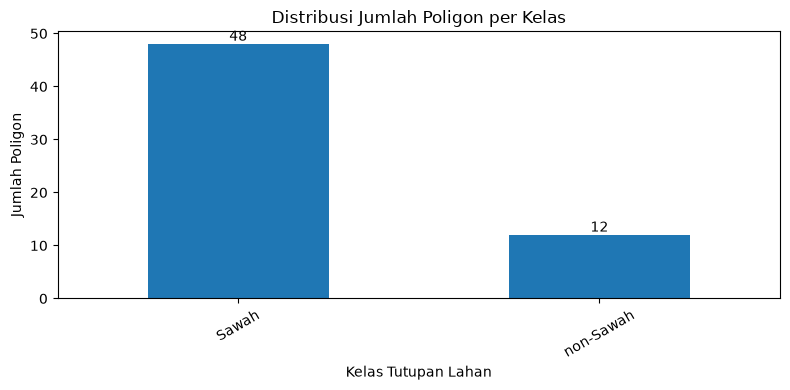

label_teks
Sawah        48
non-Sawah    12
Name: poligon_id, dtype: int64
Total poligon: 60


In [18]:
# Menghitung jumlah poligon unik per kelas
jumlah_poligon = df.groupby('label_teks')['poligon_id'].nunique()

# Visualisasi
ax = jumlah_poligon.plot(kind='bar', figsize=(8, 4))

plt.title('Distribusi Jumlah Poligon per Kelas')
plt.xlabel('Kelas Tutupan Lahan')
plt.ylabel('Jumlah Poligon')
plt.xticks(rotation=30)

# Menampilkan angka di atas batang
for i, nilai in enumerate(jumlah_poligon):
    ax.text(i, nilai, str(nilai), ha='center', va='bottom')

plt.tight_layout()
plt.show()

print(jumlah_poligon)
print("Total poligon:", jumlah_poligon.sum())

#### Penentuan Fitur

Penentuan fitur adalah pemilihan variabel yang digunakan model untuk mengenali jenis tutupan lahan. Fitur yang digunakan terdiri dari 5 band Sentinel-2 dan 4 indeks spektral, sehingga terdapat 9 fitur sebagai dasar klasifikasi.

In [19]:
fitur = [
    'B02', 'B03', 'B04', 'B08', 'B11',
    'NDVI', 'NDWI', 'MNDWI', 'NDBI'
]

X = df[fitur]
y = df['label_teks']

#### Pembagian Data Training dan Testing 80:20

Pembagian data 80:20 adalah proses membagi dataset menjadi 80% data training untuk melatih model mengenali pola tutupan lahan dan 20% data testing untuk mengukur kemampuan model dalam mengklasifikasikan data yang belum pernah dipelajari.

In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print('Data training:', len(X_train))
print('Data testing :', len(X_test))

Data training: 76
Data testing : 19


#### StandardScaler

StandardScaler adalah metode untuk menyamakan skala nilai setiap fitur agar memiliki rata-rata 0 dan standar deviasi 1. Tujuannya supaya fitur dengan nilai besar tidak mendominasi perhitungan jarak pada algoritma KNN.

In [21]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## Modeling

Modeling adalah tahap membangun dan melatih model K-Nearest Neighbors (KNN) menggunakan data training. KNN mengklasifikasikan tutupan lahan berdasarkan kemiripan fitur dengan sejumlah data terdekat.

In [24]:
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_scaled, y_train)

y_pred_knn = knn_model.predict(X_test_scaled)

## Evaluation

### Accuracy dan F1-Score

Accuracy adalah ukuran persentase prediksi model yang benar dari seluruh data uji. Sementara itu, F1-Score adalah ukuran keseimbangan antara precision (ketepatan prediksi) dan recall (kemampuan mengenali kelas), terutama saat jumlah data setiap kelas tidak seimbang.

In [25]:
accuracy = accuracy_score(y_test, y_pred_knn)
f1_macro = f1_score(y_test, y_pred_knn, average='macro')
f1_weighted = f1_score(y_test, y_pred_knn, average='weighted')

print(f'Accuracy    : {accuracy:.4f}')
print(f'F1 Macro   : {f1_macro:.4f}')
print(f'F1 Weighted: {f1_weighted:.4f}')

Accuracy    : 1.0000
F1 Macro   : 1.0000
F1 Weighted: 1.0000


### Classification Report

In [26]:
print(classification_report(y_test, y_pred_knn))

              precision    recall  f1-score   support

       Sawah       1.00      1.00      1.00        17
   non-Sawah       1.00      1.00      1.00         2

    accuracy                           1.00        19
   macro avg       1.00      1.00      1.00        19
weighted avg       1.00      1.00      1.00        19



### Confusion Matrix

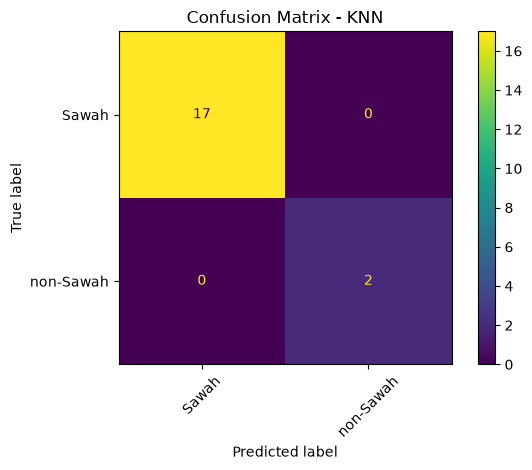

In [27]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_knn,
    xticks_rotation=45
)

plt.title('Confusion Matrix - KNN')
plt.tight_layout()
plt.show()

### Evaluasi Tingkat Polygon

Prediksi piksel pada data uji dikelompokkan berdasarkan `poligon_id`. Kelas akhir setiap polygon ditentukan menggunakan mayoritas prediksi piksel.

In [28]:
hasil_test = df.loc[
    X_test.index,
    ['poligon_id', 'label_teks']
].copy()

hasil_test['prediksi'] = y_pred_knn

eval_poligon = (
    hasil_test
    .groupby('poligon_id')
    .agg(
        kelas_aktual=('label_teks', 'first'),
        kelas_prediksi=('prediksi', lambda x: x.mode().iloc[0]),
        jumlah_piksel=('prediksi', 'size')
    )
    .reset_index()
)

eval_poligon['benar'] = (
    eval_poligon['kelas_aktual'] ==
    eval_poligon['kelas_prediksi']
)

print('Total polygon uji:', len(eval_poligon))
print('Polygon benar    :', int(eval_poligon['benar'].sum()))
print('Polygon salah    :', int((~eval_poligon['benar']).sum()))
print('Akurasi polygon  :', round(eval_poligon['benar'].mean(), 4))

Total polygon uji: 16
Polygon benar    : 16
Polygon salah    : 0
Akurasi polygon  : 1.0


## Peta Interaktif Evaluasi Polygon

In [29]:
gdf_eval = gdf.merge(
    eval_poligon,
    on='poligon_id',
    how='left'
)

WARNA_KELAS = {
    'Sawah': '#90EE90',
    'non-Sawah': '#FF0000',
}

minx, miny, maxx, maxy = gdf_eval.total_bounds

m = folium.Map(
    location=[(miny + maxy) / 2, (minx + maxx) / 2],
    zoom_start=8,
    tiles=None
)

folium.TileLayer(
    tiles='https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}',
    attr='Esri World Imagery',
    name='Esri Satellite',
    overlay=False
).add_to(m)

folium.TileLayer('OpenStreetMap', name='OpenStreetMap').add_to(m)

for kelas, warna in WARNA_KELAS.items():
    sub = gdf_eval[gdf_eval['label_teks'] == kelas]

    folium.GeoJson(
        sub,
        name=kelas,
        style_function=lambda feature, warna=warna: {
            'color': warna,
            'fillColor': warna,
            'weight': 2,
            'fillOpacity': 0.45
        },
        tooltip=folium.GeoJsonTooltip(
            fields=['poligon_id', 'label_teks', 'kelas_prediksi', 'benar'],
            aliases=['Polygon:', 'Kelas Asli:', 'Prediksi:', 'Benar:']
        )
    ).add_to(m)

salah = gdf_eval[gdf_eval['benar'] == False]

if len(salah) > 0:
    folium.GeoJson(
        salah,
        name='Salah Klasifikasi',
        style_function=lambda feature: {
            'color': '#ff7800',
            'weight': 4,
            'fill': False,
            'dashArray': '6, 4'
        }
    ).add_to(m)

folium.LayerControl(collapsed=False).add_to(m)
m.fit_bounds([[miny, minx], [maxy, maxx]])

m.save(HASIL / 'peta_evaluasi_knn.html')
m